<a href="https://colab.research.google.com/github/shuk95/GeneralProjects/blob/main/AAPLStockPredictionNeilShukla06152023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[*********************100%***********************]  1 of 1 completed
Epoch 1/10
84/84 [==============================] - 10s 64ms/step - loss: 0.0021
Epoch 2/10
84/84 [==============================] - 4s 47ms/step - loss: 1.6224e-04
Epoch 3/10
84/84 [==============================] - 5s 61ms/step - loss: 1.1926e-04
Epoch 4/10
84/84 [==============================] - 4s 50ms/step - loss: 1.2681e-04
Epoch 5/10
84/84 [==============================] - 4s 49ms/step - loss: 1.0553e-04
Epoch 6/10
84/84 [==============================] - 5s 65ms/step - loss: 9.2530e-05
Epoch 7/10
84/84 [==============================] - 4s 47ms/step - loss: 1.0049e-04
Epoch 8/10
84/84 [==============================] - 4s 48ms/step - loss: 9.1651e-05
Epoch 9/10
84/84 [==============================] - 5s 62ms/step - loss: 9.3021e-05
Epoch 10/10
20/20 [==============================] - 0s 14ms/step


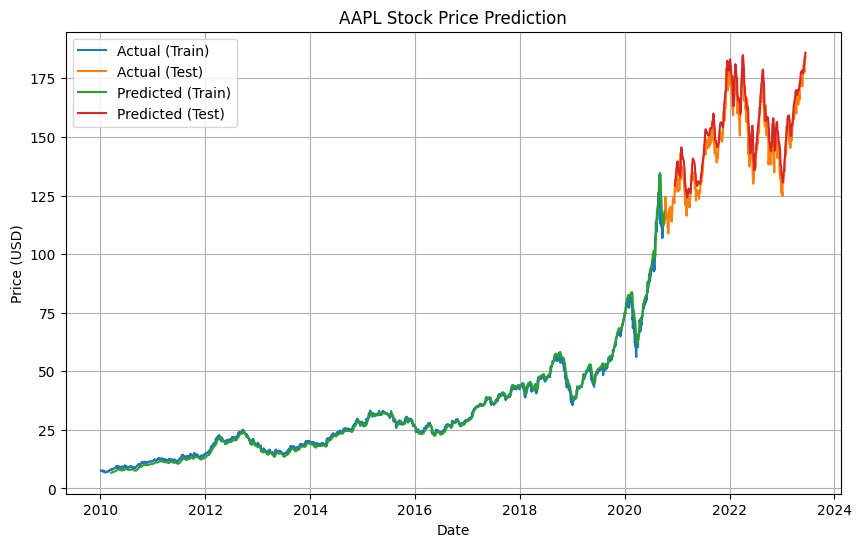

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
import matplotlib.pyplot as plt

# Define the ticker symbol for the stock
ticker_symbol = 'AAPL'

# Fetch historical stock prices from Yahoo Finance
stock_data = yf.download(ticker_symbol, start='2010-01-01', end='2024-12-31')

# Extract the 'Close' prices from the stock data
stock_prices = stock_data['Close']

# Normalize the stock prices
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_prices = scaler.fit_transform(stock_prices.values.reshape(-1, 1))

# Split the data into training and testing sets
split_index = int(0.8 * len(scaled_prices))
train_data = scaled_prices[:split_index]
test_data = scaled_prices[split_index:]

# Function to create sequences and corresponding labels
def create_sequences(data, sequence_length):
    X = []
    y = []
    for i in range(len(data) - sequence_length):
        X.append(data[i:i+sequence_length])
        y.append(data[i+sequence_length])
    return np.array(X), np.array(y)

# Set the sequence length for creating input sequences
sequence_length = 50

# Create training sequences and labels
X_train, y_train = create_sequences(train_data, sequence_length)

# Create testing sequences and labels
X_test, y_test = create_sequences(test_data, sequence_length)

# Build an LSTM model
model = Sequential()
model.add(LSTM(50, return_sequences=True, input_shape=(sequence_length, 1)))
model.add(LSTM(50))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mean_squared_error')

# Train the model
model.fit(X_train, y_train, epochs=10, batch_size=32, verbose=1)

# Predict the stock prices
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

# Invert the scaling of the predictions
train_predictions = scaler.inverse_transform(train_predictions)
test_predictions = scaler.inverse_transform(test_predictions)

# Plot the predicted prices
plt.figure(figsize=(10, 6))
plt.plot(stock_prices.index[:split_index], stock_prices[:split_index], label='Actual (Train)')
plt.plot(stock_prices.index[split_index:], stock_prices[split_index:], label='Actual (Test)')
plt.plot(stock_prices.index[sequence_length:split_index], train_predictions, label='Predicted (Train)')
plt.plot(stock_prices.index[split_index+sequence_length:], test_predictions, label='Predicted (Test)')
plt.title(f"{ticker_symbol} Stock Price Prediction")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()